In [1]:
# Data Science, Assignment - 1
# Question 2

# Data Preprocessing
import sklearn
import pandas as pd
import numpy as np

from sklearn.datasets import fetch_kddcup99
kdd = fetch_kddcup99(subset=None, as_frame=True)
X = kdd.data.copy()

print("RAW DATA INFORMATION \n")
print("Rows (raw data) : ", X.shape[0])
print("Columns (raw data) : ", X.shape[1])
print("Columns in dataset : ")
print(list(X.columns))

# Raw Data Transformation
print("\n")
one_hot_cols = ['protocol_type', 'service', 'flag']
numeric_cols = [c for c in X.columns if c not in one_hot_cols]
X[numeric_cols] = X[numeric_cols].astype(float)
X = pd.get_dummies(X, columns=one_hot_cols) # one hot encoding
X = X.loc[:, X.nunique()>1] # removing constant columns
D = X.to_numpy(dtype=np.float32)
D = (D - D.min(axis=0))/(D.max(axis=0) - D.min(axis=0)) # normalization


print("TRANSFORMED DATA INFORMATION \n")
print("Rows (data matrix) : ", D.shape[0])
print("Columns (data matrix): ", D.shape[1])
print("Columns in dataset : ")
print(list(X.columns))
print(D.shape)
print("\n")

RAW DATA INFORMATION 

Rows (raw data) :  494021
Columns (raw data) :  41
Columns in dataset : 
['duration', 'protocol_type', 'service', 'flag', 'src_bytes', 'dst_bytes', 'land', 'wrong_fragment', 'urgent', 'hot', 'num_failed_logins', 'logged_in', 'num_compromised', 'root_shell', 'su_attempted', 'num_root', 'num_file_creations', 'num_shells', 'num_access_files', 'num_outbound_cmds', 'is_host_login', 'is_guest_login', 'count', 'srv_count', 'serror_rate', 'srv_serror_rate', 'rerror_rate', 'srv_rerror_rate', 'same_srv_rate', 'diff_srv_rate', 'srv_diff_host_rate', 'dst_host_count', 'dst_host_srv_count', 'dst_host_same_srv_rate', 'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate', 'dst_host_srv_diff_host_rate', 'dst_host_serror_rate', 'dst_host_srv_serror_rate', 'dst_host_rerror_rate', 'dst_host_srv_rerror_rate']


TRANSFORMED DATA INFORMATION 

Rows (data matrix) :  494021
Columns (data matrix):  116
Columns in dataset : 
['duration', 'src_bytes', 'dst_bytes', 'land', 'wrong_fragment'

In [2]:
import time
import matplotlib.pyplot as plt

SEED = 42
rng = np.random.default_rng(SEED)
OriginalD=D
y = (kdd.target != b'normal.').to_numpy(dtype=float)

D = D.astype(np.float64)
n, d = D.shape
rankD = np.linalg.matrix_rank(D)
print("n =", n, " d =", d, " rank(D) =", rankD)
print("attacks:", int(y.sum()), " normal:", int(n - y.sum()))

def loss(D, y, a):
    res = D @ a - y
    return float(res @ res)

n = 494021  d = 116  rank(D) = 113
attacks: 396743  normal: 97278


In [3]:
tInit = time.perf_counter()
b = np.linalg.lstsq(D, y, rcond=None)[0]
timeTakenOriginal = time.perf_counter() - tInit

lossOriginal = loss(D, y, b)
print("\nQ2(a)")
print(f"Loss(D, y, b)     = {lossOriginal:.4f}")
print(f"Time to compute b = {timeTakenOriginal:.3f} secs")


Q2(a)
Loss(D, y, b)     = 2949.7888
Time to compute b = 6.301 secs



Q2(b) all runs
   m  epoch  Loss(D,y,a~)   ratio  sketched loss  time (s)
  50      1       10002.3 3.39085     1.5458e-23   2.71507
  50      2       10223.1 3.46571    1.12837e-23   1.88472
  50      3       9796.73 3.32116    1.76782e-24   1.82562
  50      4       8890.59 3.01398     4.5293e-24   1.81649
  50      5         16756 5.68042    3.85078e-23   1.78694
 100      1       30557.9 10.3593    7.88674e-24   1.83257
 100      2       57980.6 19.6559     2.0801e-23     3.021
 100      3       82239.5 27.8798    5.04111e-24   2.19264
 100      4       33775.8 11.4503    1.03818e-23   1.81664
 100      5       19417.9 6.58281    1.59525e-23   1.79994
 200      1       7993.99 2.71002        1448.86   1.82088
 200      2       7108.06 2.40969        1231.78   1.81932
 200      3       6754.32 2.28976         1246.7   2.45775
 200      4       7284.11 2.46937        1034.15   2.38412
 200      5       5391.45 1.82774         1412.2   1.81881
 500      1       3827.07 1.29741       

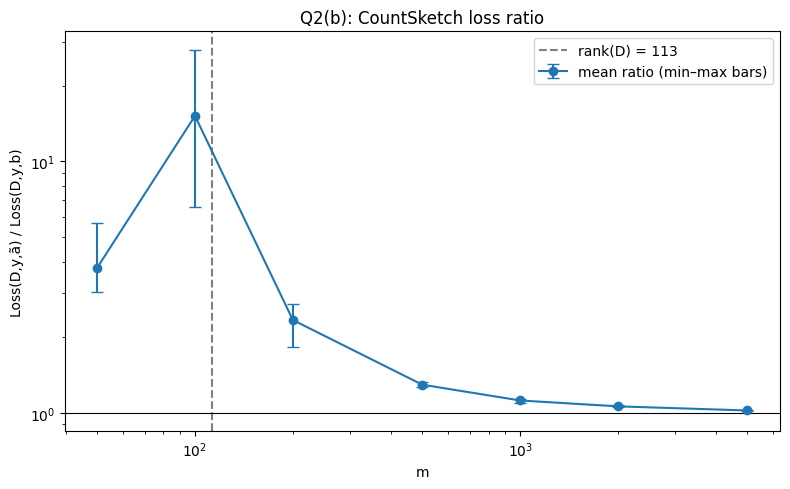

In [4]:
def countsketch(D, y, m, rng):
    nRows = D.shape[0]
    h = rng.integers(0, m, size=nRows)
    sigma = rng.choice([-1.0, 1.0], size=nRows)
    SD = np.zeros((m, D.shape[1]))
    np.add.at(SD, h, sigma[:, None] * D)
    Sy = np.zeros(m)
    np.add.at(Sy, h, sigma * y)
    return SD, Sy


mValues = [50, 100, 200, 500, 1000, 2000, 5000]
EPOCHS = 5
rows = []

for m in mValues:
    for epoch in range(EPOCHS):
        tInit = time.perf_counter()
        SD, Sy = countsketch(D, y, m, rng)
        aTilde = np.linalg.lstsq(SD, Sy, rcond=None)[0]
        tSketch = time.perf_counter() - tInit

        trueLoss = loss(D, y, aTilde)
        skLoss = loss(SD, Sy, aTilde)
        rows.append({"m": m, "epoch": epoch + 1,
                     "Loss(D,y,a~)": trueLoss,
                     "ratio": trueLoss / lossOriginal,
                     "sketched loss": skLoss,
                     "time (s)": tSketch})

resultBpart = pd.DataFrame(rows)
pd.set_option("display.float_format", lambda v: f"{v:.6g}")
print("\nQ2(b) all runs")
print(resultBpart.to_string(index=False))


conciseBpart = resultBpart.groupby("m").agg(
    mean_loss=("Loss(D,y,a~)", "mean"),
    mean_ratio=("ratio", "mean"),
    min_ratio=("ratio", "min"),
    max_ratio=("ratio", "max"),
    mean_sketched_loss=("sketched loss", "mean"),
    mean_time=("time (s)", "mean"),
)
print("\nQ2(b) summary over 5 runs")
print(conciseBpart.to_string())

meanRatio = conciseBpart["mean_ratio"].to_numpy()
errorBound = [meanRatio - conciseBpart["min_ratio"].to_numpy(),
        conciseBpart["max_ratio"].to_numpy() - meanRatio]

fig, ax = plt.subplots(figsize=(8, 5))
ax.errorbar(mValues, meanRatio, yerr=errorBound, fmt="o-", capsize=4, label="mean ratio (min–max bars)")
ax.axvline(rankD, color="gray", ls="--", label=f"rank(D) = {rankD}")
ax.axhline(1, color="black", lw=0.8)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("m"); ax.set_ylabel("Loss(D,y,ã) / Loss(D,y,b)")
ax.set_title("Q2(b): CountSketch loss ratio")
ax.legend()
plt.tight_layout()
plt.savefig("q2b_ratio.png", dpi=150)
plt.show()

Describe what happens to the ratio and to the sketched
loss below and above m = rank(D).

The Sketched Loss is low for m < rank(D) since there are infinitely many vectors a can fit therefore a can fit these m vectors upto a great extent and loss is small where as m increases (> rank(D)) loss gradually increases.
But for the Ratio its opposite as m>rank(D) ratio narrows to 1 showing that our solution fits well on full dataset D as well.

The spread between runs also narrows

In [5]:
summaryCpart = pd.DataFrame({
    "mean time (s)": conciseBpart["mean_time"],
    "time for b (s)": timeTakenOriginal,
    "speed-up": timeTakenOriginal / conciseBpart["mean_time"],
})
print("\nQ2(c)")
print(summaryCpart.to_string())


Q2(c)
      mean time (s)  time for b (s)  speed-up
m                                            
50          2.00577         6.30054   3.14121
100         2.13256         6.30054   2.95445
200         2.06018         6.30054   3.05825
500         2.06616         6.30054   3.04939
1000        1.82374         6.30054   3.45474
2000        2.12362         6.30054   2.96689
5000        2.21827         6.30054   2.84029


m = 50: mean = 0.9879, std = 0.1826
m = 500: mean = 1.0024, std = 0.0650
m = 5000: mean = 0.9982, std = 0.0207


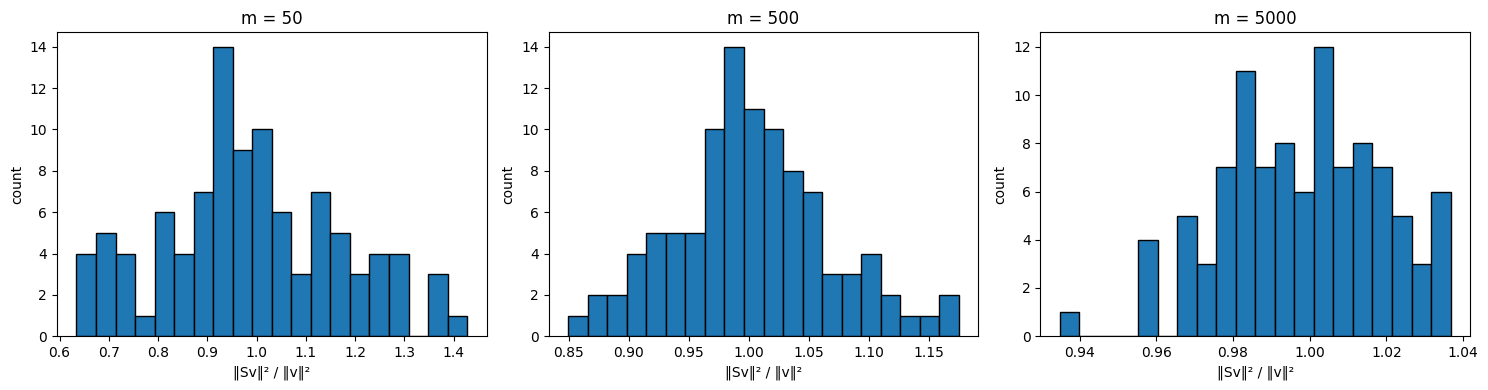

In [6]:
# Q2 (d)
v = D @ b - y
vNorm2 = v @ v

mValuesD = [50, 500, 5000]
DRAWS = 100
ratiosD = {}

for m in mValuesD:
    ratio = np.empty(DRAWS)
    for t in range(DRAWS):
        h = rng.integers(0, m, size=v.shape[0])
        sigma = rng.choice([-1.0, 1.0], size=v.shape[0])
        Sv = np.zeros(m)
        np.add.at(Sv, h, sigma * v)
        ratio[t] = (Sv @ Sv) / vNorm2
    ratiosD[m] = ratio
    print(f"m = {m}: mean = {ratio.mean():.4f}, std = {ratio.std():.4f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for axe, m in zip(axes, mValuesD):
    axe.hist(ratiosD[m], bins=20, edgecolor="black")
    axe.set_title(f"m = {m}")
    axe.set_xlabel("‖Sv‖² / ‖v‖²")
    axe.set_ylabel("count")
plt.tight_layout()
plt.show()

How does the spread change with m?

As m increases the spread decreases towards 0.The standard deviation scales like 1/√m

In [7]:
subsetRows = 50_000
m = 500
EPOCHS = 5

randomRows = np.random.default_rng(42)
idx = randomRows.choice(D.shape[0], size=subsetRows, replace=False)
Dk, yk = D[idx], y[idx]

bk = np.linalg.lstsq(Dk, yk, rcond=None)[0]
lossK = loss(Dk, yk, bk)
print(f"\nQ2(e)  Loss(D', y', b') = {lossK:.4f}")

resultRows = []
for epoch in range(EPOCHS):
    tInit = time.perf_counter()
    SD, Sy = countsketch(Dk, yk, m, rng)
    timeRquiredCS = time.perf_counter() - tInit
    aCountSketch = np.linalg.lstsq(SD, Sy, rcond=None)[0]
    resultRows.append({"sketch": "CountSketch", "epoch": epoch + 1,
                   "time (s)": timeRquiredCS,
                   "ratio": loss(Dk, yk, aCountSketch) / lossK})

    tInit = time.perf_counter()
    S = rng.normal(0.0, 1.0 / np.sqrt(m), size=(m, subsetRows))
    SD, Sy = S @ Dk, S @ yk
    timeReuiredDense = time.perf_counter() - tInit
    aDenseS = np.linalg.lstsq(SD, Sy, rcond=None)[0]
    resultRows.append({"sketch": "Gaussian", "epoch": epoch + 1,
                   "time (s)": timeReuiredDense,
                   "ratio": loss(Dk, yk, aDenseS) / lossK})
    del S

resultEpart = pd.DataFrame(resultRows)
print(resultEpart.to_string(index=False))
summaryEpart = resultEpart.groupby("sketch")[["time (s)", "ratio"]].mean()
print("\nQ2(e) averages over 5 repetitions (m = 500, n' = 50,000)")
print(summaryEpart.to_string())

nFull = D.shape[0]
print(f"\nDense S for full D at m = {m}: {m} x {nFull} = {m * nFull / 1e6:.0f}M entries ")


Q2(e)  Loss(D', y', b') = 275.1544
     sketch  epoch  time (s)   ratio
CountSketch      1  0.170321 1.25051
   Gaussian      1  0.756972 1.24365
CountSketch      2  0.242699 1.23177
   Gaussian      2   1.02625 1.25779
CountSketch      3  0.257859 1.30729
   Gaussian      3  0.996873 1.26521
CountSketch      4  0.169901 1.30611
   Gaussian      4  0.689243 1.23336
CountSketch      5  0.168856 1.29219
   Gaussian      5  0.720178 1.31462

Q2(e) averages over 5 repetitions (m = 500, n' = 50,000)
             time (s)   ratio
sketch                       
CountSketch  0.201927 1.27758
Gaussian     0.837902 1.26293

Dense S for full D at m = 500: 500 x 494021 = 247M entries 


Which sketch would you use on the full D?

I would definitely use CountSketch since we are nearly getting the same ratio but in computation time there is a huge difference.Also memory wise it is cheaper.